In [ ]:
from filemanager import FileManager
fm = FileManager('assets','H05','foo')
# fm.id_block = 'qc'
# fm.timestamp()
# fn = fm.get_filepath('whole','svg')
# plt.savefig(fn)

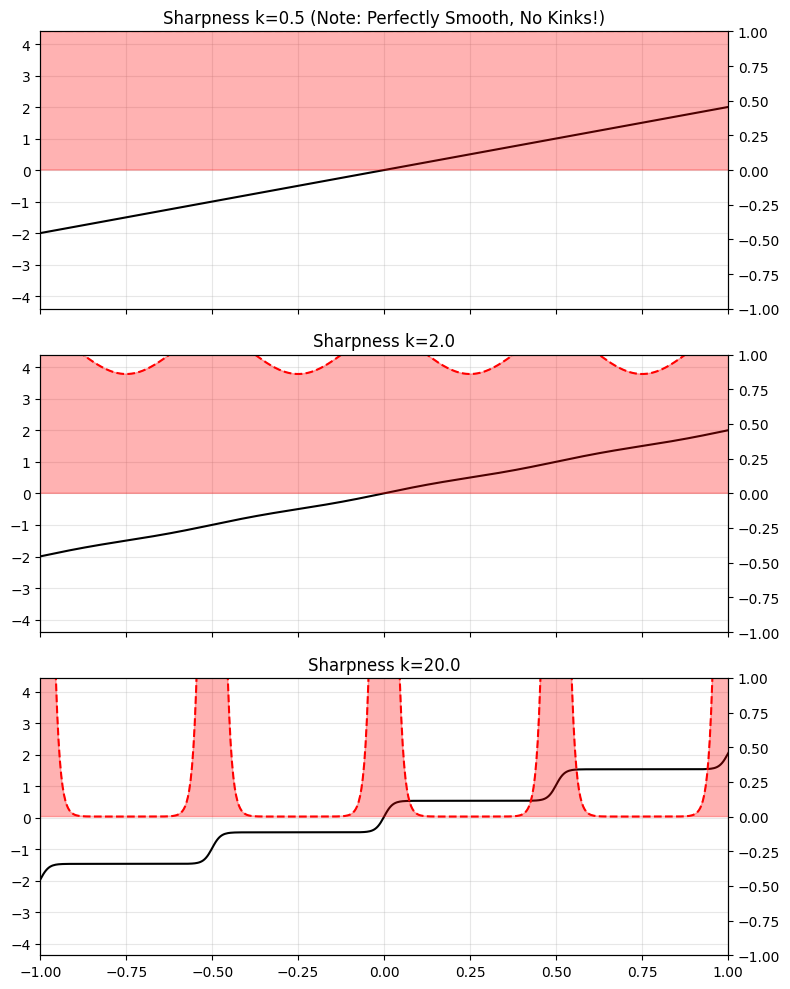

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_smooth_staircase_pulse(
    x: np.ndarray, 
    density: float = 5.0, 
    sharpness: float = 2.0
) -> tuple[np.ndarray, np.ndarray]:
    """
    Generates a perfectly smooth (C-infinity) Staircase and Pulse Train.
    
    Instead of finding the nearest integer (which causes kinks), 
    this calculates the superposition of all relevant smooth steps.
    
    S(u) = Sum_n [ 0.5 * (1 + tanh(k * (u - n))) ] - Offset
    """
    
    # 1. Phase Coordinate
    u = x * density
    
    # 2. Determine summation range (Integer indices)
    # We need to sum over integers 'n' that are close enough to the current 'u'.
    # Tanh decays to +/- 1.0 when |k*delta| > 5 roughly.
    # So we need margin > 5 / sharpness.
    margin = int(np.ceil(10.0 / (sharpness + 1e-5))) + 2
    
    n_min = int(np.floor(u.min())) - margin
    n_max = int(np.ceil(u.max())) + margin
    
    # Create a grid of integer indices [1, N_integers]
    n_indices = np.arange(n_min, n_max + 1)
    
    # 3. Vectorized Superposition (Broadcasting)
    # Shape of u: (M, 1)
    # Shape of n: (1, N)
    # Shape of delta: (M, N)
    u_col = u[:, np.newaxis]
    n_row = n_indices[np.newaxis, :]
    
    delta = u_col - n_row # Distance to every integer
    
    # --- Staircase Calculation ---
    # Each integer n contributes a step of height 1.
    # Step function: 0.5 * (1 + tanh(k * (u-n)))
    # Range of this function is 0 to 1.
    step_contributions = 0.5 * (1 + np.tanh(sharpness * delta))
    
    # Sum all contributions
    staircase_raw = np.sum(step_contributions, axis=1)
    
    # Centering Correction: 
    # We want S(0) to be 0 (or close to the center relative to x)
    # At u=0, the sum creates an offset based on how many negative integers we included.
    # We simply subtract the value at u=0 (or extrapolate) to zero the origin.
    # For robust centering relative to the domain origin:
    zero_idx = np.abs(u).argmin()
    staircase = staircase_raw - staircase_raw[zero_idx]
    
    # --- Pulse Train Calculation ---
    # Derivative of sum is sum of derivatives.
    # P(u) = Sum_n [ (k/2) * sech^2(k * (u-n)) ]
    
    # Clip for numerical stability of cosh
    cosh_arg = np.clip(sharpness * delta, -50, 50)
    
    # Amplitude = Sharpness / 2 (Area Conservation Rule)
    pulse_contributions = (sharpness / 2.0) * (1.0 / np.cosh(cosh_arg)**2)
    
    pulse = np.sum(pulse_contributions, axis=1)
    
    return staircase, pulse

# --- Verification Logic ---
if __name__ == "__main__":
    x_domain = np.linspace(-2, 2, 1000)
    rho = 2.0
    
    # Test very low sharpness to check for smoothness (No Kinks!)
    # k=0.5 means the steps are wider than the lattice spacing -> Strong overlap
    params = [0.5, 2.0, 20.0]
    
    fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
    
    for i, k in enumerate(params):
        S, P = generate_smooth_staircase_pulse(x_domain, density=rho, sharpness=k)
        
        ax = axes[i]
        ax.plot(x_domain, S, 'k-', label='Staircase')
        
        ax2 = ax.twinx()
        ax2.fill_between(x_domain, P, color='red', alpha=0.3)
        ax2.plot(x_domain, P, 'r--', label='Pulse')
        
        ax.set_title(f"Sharpness k={k}")
        ax.grid(True, alpha=0.3)
        
        # Highlight: Even at k=0.5, the curve is perfectly smooth sinusoidal-like
        if k < 1.0:
            ax.set_title(f"Sharpness k={k} (Note: Perfectly Smooth, No Kinks!)")
        plt.xlim([-1,1])
        plt.ylim([-1,1])

    plt.tight_layout()
    
    plt.show()

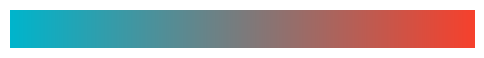

In [2]:
import matplotlib.pyplot as plt

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

first_color = colors[0]  # '#1f77b4' (tab:blue)
second_color = colors[1] # '#ff7f0e' (tab:orange)
first_color = '#E66100'
second_color ='#009E73'# colors[1] # '#ff7f0e' (tab:orange)
first_color = '#6B9AC4'
second_color ='#FF6F61'# colors[1] # '#ff7f0e' (tab:orange)
first_color = '#00B5CC'
second_color = '#F6412D'

from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list('first_to_second', [first_color, second_color])
import numpy as np

plt.figure(figsize=(6, 0.5))
plt.imshow([np.linspace(0, 1, 256)], aspect='auto', cmap=cmap)
plt.axis('off')
plt.show()


<>:30: SyntaxWarning: invalid escape sequence '\p'
<>:34: SyntaxWarning: invalid escape sequence '\p'
<>:30: SyntaxWarning: invalid escape sequence '\p'
<>:34: SyntaxWarning: invalid escape sequence '\p'
C:\Users\user\AppData\Local\Temp\ipykernel_26132\2124655970.py:30: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel("$d\phi/dx$ [arb.]")
C:\Users\user\AppData\Local\Temp\ipykernel_26132\2124655970.py:34: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel("$\phi$ [arb.]")


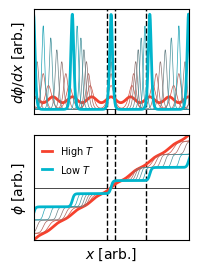

In [14]:
dw_density_start = 2
dw_density_end = 4
dw_smoothness_start = 20
dw_smoothness_end = 2.5
num_schematics = 8
l_dw = .05 

l_2pi = 1/dw_density_start
xs = [-l_dw,l_dw,l_2pi-l_dw]
dw_density = np.linspace(dw_density_start,dw_density_end,num_schematics)
dw_smoothness = np.linspace(dw_smoothness_start,dw_smoothness_end,num_schematics)

fig,ax = plt.subplots(2,1,figsize=(2,3))
for iax in range(2):
    plt.sca(ax[iax])
    for x in xs:
        plt.axvline(x=x, color='k', lw=1,ls='--')
    plt.axhline(y=0, color='k', lw=.5,ls='-')
    # 
    plt.xlim(-1,1)
# plt.ylim(-2,2)
    plt.grid(True)
    for i in reversed(range(num_schematics)):
        lw = 2 if i == 0 or i == num_schematics - 1 else .5
        label = 'Low $T$' if i == 0 else 'High $T$' if i == num_schematics - 1 else None
        phi,dlt = generate_smooth_staircase_pulse(x_domain, density=dw_density[i], sharpness=dw_smoothness[i])
        c = cmap(i/(num_schematics-1))
        if iax == 0:
            plt.plot(x_domain, dlt, c=c, lw=lw, label=label)
            plt.ylabel("$d\phi/dx$ [arb.]")
        else:
            plt.plot(x_domain, phi, c=c, lw=lw, label=label)
            plt.ylim([-4,4])
            plt.ylabel("$\phi$ [arb.]")
            plt.xlabel("$x$ [arb.]")
    

ax[1].legend(fontsize=7, frameon=False, loc='upper left', handlelength=1)
for a in ax:
    a.set_xticks([])
    a.set_yticks([])

fm.id_block = 'qc'
fm.timestamp()
fn = fm.get_filepath('whole','svg')
plt.savefig(fn)

In [ ]:
x_domain.shape

(1000,)